# Q03 - Hill Climbing for Airport Design and Gate Arrangement

Same code as `q03_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q3 - Hill climbing for airport design and gate arrangement.

A  starting state  : blueprint of an existing airport in another city
B  action selection: legal small changes a-e, move to the best neighbour (steepest ascent)
C  goal state      : best score from 10 traveller votes, waiting time, space use, senior care
"""
import os
import random

import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)
random.seed(3)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

# state = (gates, immigration counters, built area, shop zone 0-4, waiting area units)
SHOP_ZONES = ["landside", "check-in", "security", "near gates", "far airside"]
TRAVELLERS = [tuple(random.uniform(0.2, 1.0) for _ in range(4)) for _ in range(10)]


def used_space(s: tuple) -> float:
    gates, counters, _, _, waiting = s
    return 3 * gates + 1.5 * counters + waiting + 12  # 12 units are fixed (shops, toilets)


def useful_space(s: tuple) -> float:
    """Floor area that is actually busy at peak hour (idle gates or counters do not count)."""
    gates, counters, _, _, waiting = s
    return 3 * min(gates, 18) + 1.5 * min(counters, 12) + min(waiting, 2 * gates) + 12


def criteria(s: tuple) -> dict:
    gates, counters, area, shop, waiting = s
    crowd = max(0.0, 1.6 * gates - waiting) * 0.9  # too few seats -> people queue standing
    wait_min = 6 + 260 / gates + 150 / min(counters, 14) + crowd
    wait_score = min(1.0, max(0.0, (50 - wait_min) / 40))
    seats = min(1.0, waiting / (2 * gates))
    shop_fit = 1 - abs(shop - 3) / 3
    queue_fit = min(1.0, counters / 12)
    senior = 0.4 * seats + 0.3 * shop_fit + 0.3 * queue_fit - 0.015 * max(0, gates - 16)
    likes = (wait_score, seats, shop_fit, queue_fit)
    votes = sum(sum(p * x for p, x in zip(t, likes)) / sum(t) > 0.62 for t in TRAVELLERS)
    return {"wait": wait_min, "util": useful_space(s) / area, "senior": senior, "votes": votes,
            "wait_score": wait_score}


def score(s: tuple) -> float:
    c = criteria(s)
    return round(100 * (0.30 * c["votes"] / 10 + 0.30 * c["wait_score"]
                        + 0.15 * c["util"] + 0.25 * c["senior"]), 2)


ACTIONS = {
    "a: add a gate": lambda s: (s[0] + 1, s[1], s[2], s[3], s[4]),
    "b: +1 immigration counter": lambda s: (s[0], s[1] + 1, s[2], s[3], s[4]),
    "c: remove 6 units of space": lambda s: (s[0], s[1], s[2] - 6, s[3], s[4]),
    "d: shops one zone inward": lambda s: (s[0], s[1], s[2], s[3] + 1, s[4]),
    "d: shops one zone outward": lambda s: (s[0], s[1], s[2], s[3] - 1, s[4]),
    "e: waiting area +4": lambda s: (s[0], s[1], s[2], s[3], s[4] + 4),
    "e: waiting area -4": lambda s: (s[0], s[1], s[2], s[3], s[4] - 4),
}


def legal(s: tuple) -> bool:
    gates, counters, area, shop, waiting = s
    return gates >= 4 and counters >= 2 and 0 <= shop <= 4 and waiting >= 4 \
        and used_space(s) <= area


def hill_climb(start: tuple, actions: dict = ACTIONS, max_steps: int = 80):
    """Steepest-ascent hill climbing: always take the best legal neighbour."""
    current = start
    trace = [("A: blueprint", current, score(current))]
    for _ in range(max_steps):
        options = []
        for name, act in actions.items():  # B: action selection
            nxt = act(current)
            if legal(nxt):
                options.append((score(nxt), name, nxt))
        best_score, best_name, best = max(options)
        if best_score <= score(current):  # no neighbour is better -> stop (peak or local max)
            return current, trace, options
        current = best
        trace.append((best_name, best, best_score))
    return current, trace, options


def describe(s: tuple) -> str:
    return f"{s[0]} gates, {s[1]} counters, area {s[2]}, shops {SHOP_ZONES[s[3]]}, wait {s[4]}"


BLUEPRINT = (10, 6, 100, 0, 14)  # A: copied from another city's airport
final, trace, last_options = hill_climb(BLUEPRINT)
print("A  start:", describe(BLUEPRINT), f"| score {score(BLUEPRINT)}")
print(f"{'step':>4} | {'action chosen (B)':<27} | score")
for i, (name, _, sc) in enumerate(trace[1:], start=1):
    print(f"{i:>4} | {name:<27} | {sc:6.2f}")
c = criteria(final)
print("C  stopped at:", describe(final), f"| score {score(final)}")
print(f"   votes {c['votes']}/10, avg wait {c['wait']:.1f} min, space use {c['util']:.0%},"
      f" senior index {c['senior']:.2f}")
at_stop = [(name, score(act(final)), legal(act(final))) for name, act in ACTIONS.items()]


def short(name: str) -> str:
    if "+" in name or "inward" in name:
        return name.split(":")[0] + "+"
    if "-" in name or "outward" in name:
        return name.split(":")[0] + "-"
    return name.split(":")[0]


print("   moves at the stop:", "; ".join(
    f"{short(n)} {sc:.1f}" if ok else f"{short(n)[0]} blocked" for n, sc, ok in at_stop))

restarts = []
while len(restarts) < 12:
    s = (random.randint(6, 20), random.randint(3, 14), random.randrange(110, 171, 4),
         random.randint(0, 4), random.randrange(8, 40, 2))
    if legal(s):
        restarts.append(hill_climb(s))
best_restart = max(restarts, key=lambda r: score(r[0]))
print("random-restart hill climbing (12 random blueprints):")
print("   final scores:", ", ".join(f"{score(r[0]):.1f}" for r in restarts))
print("   best:", describe(best_restart[0]), f"| score {score(best_restart[0])}")

# ---------------- charts ----------------
fig, ax = plt.subplots(figsize=(8.5, 4))
for r in restarts:
    ax.plot([t[2] for t in r[1]], color="#a8c5e2", lw=1)
ax.plot([t[2] for t in best_restart[1]], color="#2a9d8f", lw=2, label="best random restart")
ax.plot([t[2] for t in trace], "o-", color="#e76f51", lw=2, ms=4, label="start = blueprint (A)")
ax.scatter([len(trace) - 1], [trace[-1][2]], s=90, color="#e76f51", zorder=4)
ax.annotate("stuck: local maximum", (len(trace) - 1, trace[-1][2]), xytext=(-20, -30),
            textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("hill-climbing step")
ax.set_ylabel("design score C (0-100)")
ax.set_title("Score per step: blueprint run vs 12 random restarts (grey)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("images/q03_chart1_score_per_step.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
names = [n for n, _, _ in at_stop]
vals = [sc for _, sc, _ in at_stop]
for i, (name, sc, ok) in enumerate(at_stop):
    if ok:
        ax.barh(i, sc, color="#e76f51" if sc < score(final) else "#2a9d8f")
    else:
        ax.barh(i, sc, color="white", edgecolor="#9ca3af", hatch="///")
        ax.text(sc + 0.15, i, "blocked: no free floor space", va="center", fontsize=8,
                color="#6b7280")
ax.set_yticks(range(len(names)), names)
ax.axvline(score(final), color="#1f2937", ls="--", label=f"current design = {score(final):.2f}")
ax.set_xlim(min(vals) - 2, max(vals) + 5)
ax.set_xlabel("score the neighbour design would get")
ax.set_title("At the stop: legal moves go downhill, uphill moves are blocked")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("images/q03_chart2_neighbours_at_stop.png")
plt.close(fig)
print("charts saved to images/")


A  start: 10 gates, 6 counters, area 100, shops landside, wait 14 | score 20.5
step | action chosen (B)           | score
   1 | e: waiting area +4          |  23.10
   2 | d: shops one zone inward    |  25.60
   3 | d: shops one zone inward    |  28.10
   4 | d: shops one zone inward    |  42.60
   5 | e: waiting area +4          |  49.90
   6 | b: +1 immigration counter   |  50.75
   7 | b: +1 immigration counter   |  51.60
   8 | a: add a gate               |  59.56
   9 | b: +1 immigration counter   |  61.97
  10 | b: +1 immigration counter   |  67.07
  11 | b: +1 immigration counter   |  68.95
  12 | b: +1 immigration counter   |  70.65
  13 | a: add a gate               |  74.74
  14 | e: waiting area +4          |  75.87
  15 | a: add a gate               |  77.88
  16 | a: add a gate               |  78.68
  17 | b: +1 immigration counter   |  79.40
C  stopped at: 14 gates, 13 counters, area 100, shops near gates, wait 26 | score 79.4
   votes 10/10, avg wait 36.1 min, space us

charts saved to images/


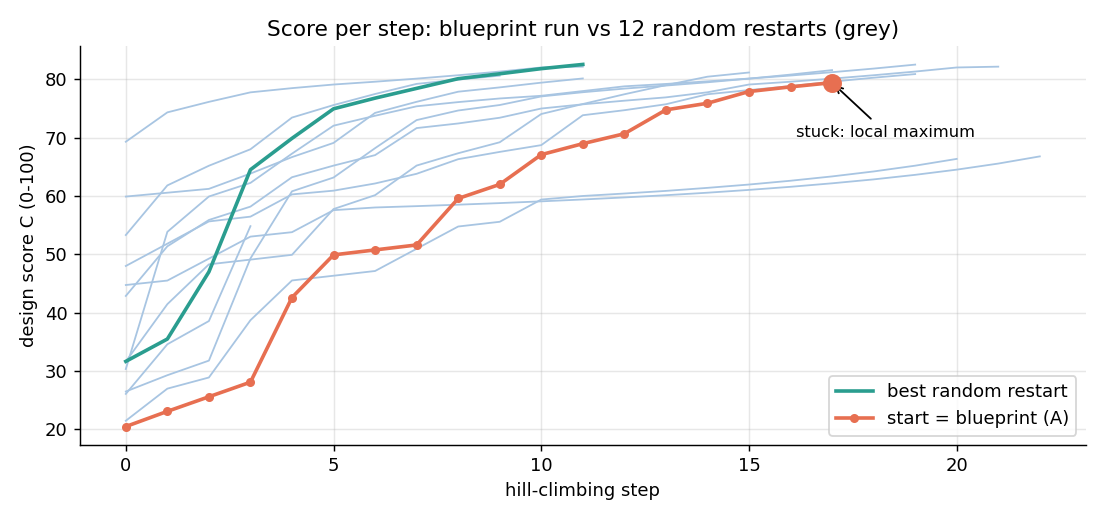

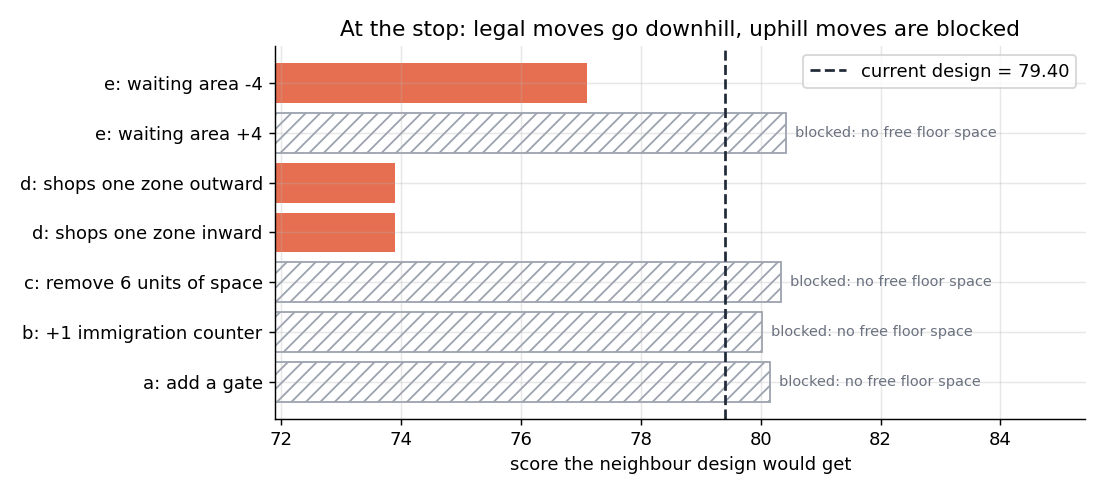

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q03_chart*.png')):
    display(Image(p))